# Figure 6 companion · Spatial structure and reference correlation

Local exploratory diagnostic using the frozen v03 prediction cache. No new
inference, training, W&B or Overleaf upload. The main Figure 6 remains unchanged.

Compare radial Fourier power and signed cross-correlation with the observed
JWST reference. Main curves use all cutouts with complete valid coverage in the
105×105 field. Subtract each image's own window-weighted mean, apply the same
Tukey window (alpha 0.5), and normalize FFTs by the window energy. Power ratios
are geometrically averaged across objects; correlations are arithmetically
averaged. Uncertainty uses 2,000 paired resamples of spatial blocks.

Raw JWST power includes noise. The outside-source spectrum is an empirical
background diagnostic, with a different smooth window; it is not an unbiased
noise estimate and is not subtracted. Supplementary checks vary the outer taper,
apply a soft source weight, and include incomplete cutouts with tapered validity.
Scale-band subsets selected by reference/background contrast are diagnostic only.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
here=Path.cwd()
workspace=here if (here/'figure_utils.py').exists() else here/'paper_figures'
if str(workspace) not in sys.path: sys.path.insert(0,str(workspace))
from figure_utils import ROOT, FIGURES, COLORS, style, read_json, sha, export
%matplotlib inline
style()
VERSION='v01'
path=FIGURES/'inputs'/f'spatial_spectra_{VERSION}.json'
result=read_json(path)
assert result['complete'] and result['local_only'] and result['split']=='validation'
assert sha(ROOT/result['arrays_path'])==result['arrays_sha256']
names=result['methods']
labels={'bilinear':'Bilinear','bicubic':'Bicubic','diffusion':'Diffusion (1 sample)',
        'diffusion_mean3':'Diffusion (mean of 3)','legacy':'ResNet','direct5':'ResNet-D5'}
colors={**COLORS,'diffusion_mean3':'#B485B8'}
nrings=len(result['radial_edges_cycles_per_pixel'])-1
frequency=np.array(result['frequencies_cycles_per_pixel'][:nrings])
# Measured target-grid pixel scale ranges 0.0593416–0.0593454 arcsec;
# use the sample median solely for axis conversion, not image resampling.
pixel_scale=.05934367
scale=pixel_scale/frequency
native_nyquist_scale=10*pixel_scale
main=result['summaries']['tukey50']
print(f"Primary population: {main['objects']:,} / {len(result['object_ids']):,}; complete common-valid coverage.")
print('Background diagnostic population:',len(result['reference_background_ids']))
print('No inference or external uploads.')


Primary population: 1,363 / 2,118; complete common-valid coverage.
Background diagnostic population: 1356
No inference or external uploads.


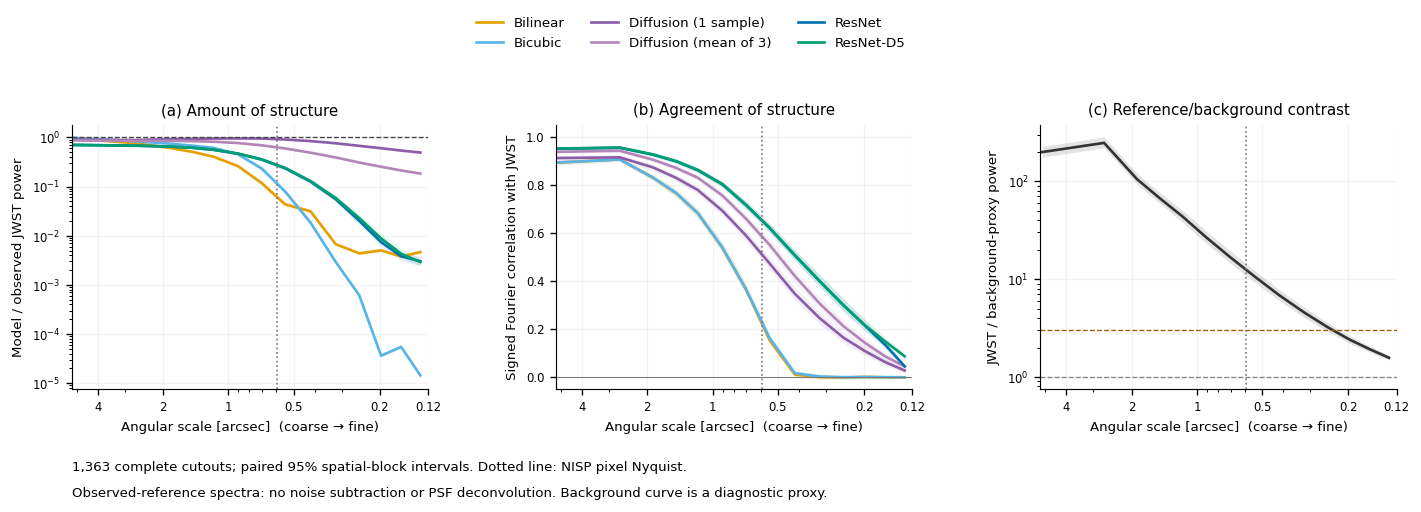

Exported: fig06_spatial_structure_v01.pdf, fig06_spatial_structure_v01.svg, fig06_spatial_structure_v01.png


[PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig06_spatial_structure_v01.pdf'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig06_spatial_structure_v01.svg'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig06_spatial_structure_v01.png')]

In [2]:
def scale_axis(ax):
    ax.set_xscale('log')
    ax.set_xlim(scale[0]*1.02,scale[-1]/1.02)
    ticks=[4,2,1,.5,.2,.12]
    ax.set_xticks(ticks,[str(t) for t in ticks])
    ax.set_xlabel('Angular scale [arcsec]  (coarse → fine)')
    ax.axvline(native_nyquist_scale,color='#777777',ls=':',lw=1)
    ax.grid(alpha=.15)

fig,axes=plt.subplots(1,3,figsize=(12,4.0))
for name in names:
    for ax,key,exponent in [(axes[0],'log_power_ratio',True),(axes[1],'correlation',False)]:
        rec=main['methods'][name][key]
        y=np.array(rec['mean'][:nrings]);ci=np.array(rec['ci95'][:nrings])
        if exponent:y=10**y;ci=10**ci
        ax.plot(scale,y,color=colors[name],label=labels[name],lw=1.6)
        ax.fill_between(scale,ci[:,0],ci[:,1],color=colors[name],alpha=.10,lw=0)
axes[0].set_yscale('log');axes[0].axhline(1,color='#444444',ls='--',lw=.8)
axes[0].set_ylabel('Model / observed JWST power')
axes[0].set_title('(a) Amount of structure')
axes[1].set_ylim(-.05,1.05);axes[1].axhline(0,color='#777777',lw=.6)
axes[1].set_ylabel('Signed Fourier correlation with JWST')
axes[1].set_title('(b) Agreement of structure')
noise=result['reference_background_log_ratio']
y=10**np.array(noise['mean'][:nrings]);ci=10**np.array(noise['ci95'][:nrings])
axes[2].plot(scale,y,color='#333333',lw=1.6)
axes[2].fill_between(scale,ci[:,0],ci[:,1],color='#777777',alpha=.2,lw=0)
axes[2].axhline(1,color='#888888',ls='--',lw=.8)
axes[2].axhline(3,color='#A65E00',ls='--',lw=.8)
axes[2].set_yscale('log');axes[2].set_ylabel('JWST / background-proxy power')
axes[2].set_title('(c) Reference/background contrast')
for ax in axes:scale_axis(ax)
handles,legend_labels=axes[0].get_legend_handles_labels()
fig.legend(handles,legend_labels,loc='upper center',ncol=3,frameon=False,bbox_to_anchor=(.5,1.05),fontsize=8)
fig.subplots_adjust(left=.07,right=.99,top=.80,bottom=.25,wspace=.36)
fig.text(.07,.08,f"{main['objects']:,} complete cutouts; paired 95% spatial-block intervals. Dotted line: NISP pixel Nyquist.",fontsize=8)
fig.text(.07,.025,'Observed-reference spectra: no noise subtraction or PSF deconvolution. Background curve is a diagnostic proxy.',fontsize=8)
plt.show()
export(fig,f'fig06_spatial_structure_{VERSION}','06b_spatial_structure.ipynb',
       [path],dict(primary_objects=main['objects'],window=result['main_window'],
                   power=result['power'],correlation=result['correlation'],pixel_scale_arcsec=pixel_scale),
       status='Local exploratory power and phase-correlation comparison; noisy observed reference')


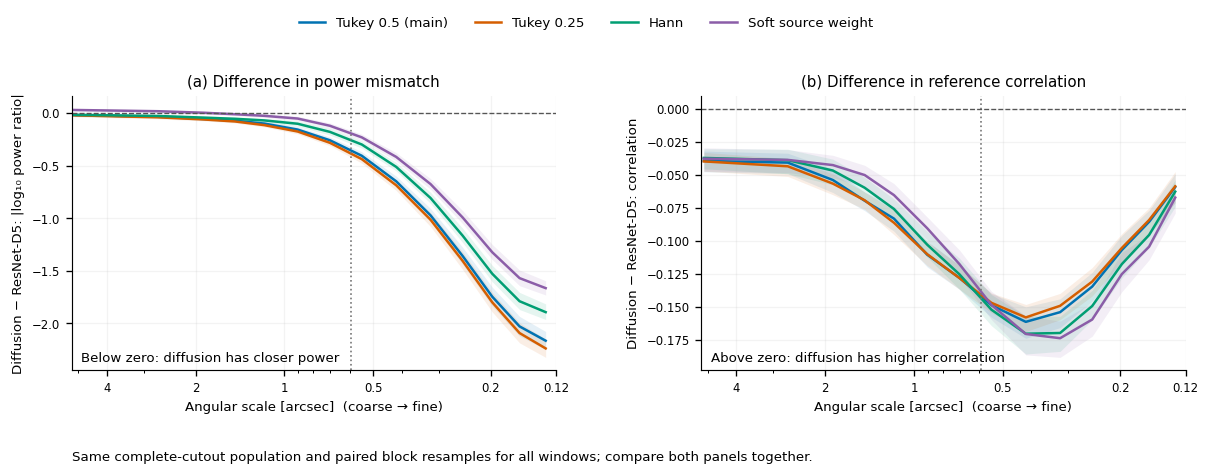

Exported: fig06_spectral_window_checks_v01.pdf, fig06_spectral_window_checks_v01.svg, fig06_spectral_window_checks_v01.png


,band,objects,method,power_ratio,correlation
0,large_15_30px,1312,Bilinear,0.436173,0.724836
1,large_15_30px,1312,Bicubic,0.618126,0.725418
2,large_15_30px,1312,Diffusion (1 sample),0.944956,0.813136
3,large_15_30px,1312,Diffusion (mean of 3),0.839377,0.860233
4,large_15_30px,1312,ResNet,0.610590,0.891091
5,large_15_30px,1312,ResNet-D5,0.609698,0.891695
6,intermediate_6_15px,944,Bilinear,0.055763,0.348939
7,intermediate_6_15px,944,Bicubic,0.097059,0.368086
8,intermediate_6_15px,944,Diffusion (1 sample),0.883808,0.642658
9,intermediate_6_15px,944,Diffusion (mean of 3),0.687310,0.721910


In [3]:
fig,axes=plt.subplots(1,2,figsize=(10.2,4.0))
case_labels={'tukey50':'Tukey 0.5 (main)','tukey25':'Tukey 0.25','hann':'Hann','soft_source':'Soft source weight'}
case_colors={'tukey50':'#0072B2','tukey25':'#D55E00','hann':'#009E73','soft_source':'#8B5DA8'}
for case,label in case_labels.items():
    paired=result['paired_diffusion_vs_resnet']['direct5'][case]
    for ax,key in zip(axes,['absolute_log_power_error_difference','correlation_difference']):
        rec=paired[key];y=np.array(rec['mean'][:nrings]);ci=np.array(rec['ci95'][:nrings])
        ax.plot(scale,y,color=case_colors[case],label=label,lw=1.5)
        ax.fill_between(scale,ci[:,0],ci[:,1],color=case_colors[case],alpha=.1,lw=0)
axes[0].set_title('(a) Difference in power mismatch')
axes[0].set_ylabel('Diffusion − ResNet-D5: |log₁₀ power ratio|')
axes[1].set_title('(b) Difference in reference correlation')
axes[1].set_ylabel('Diffusion − ResNet-D5: correlation')
for ax in axes:scale_axis(ax);ax.axhline(0,color='#555555',lw=.8,ls='--')
axes[0].text(.02,.03,'Below zero: diffusion has closer power',transform=axes[0].transAxes,fontsize=8)
axes[1].text(.02,.03,'Above zero: diffusion has higher correlation',transform=axes[1].transAxes,fontsize=8)
handles,legend_labels=axes[0].get_legend_handles_labels()
fig.legend(handles,legend_labels,loc='upper center',ncol=4,frameon=False,bbox_to_anchor=(.5,1.01),fontsize=8)
fig.subplots_adjust(left=.08,right=.99,top=.82,bottom=.25,wspace=.3)
fig.text(.08,.06,'Same complete-cutout population and paired block resamples for all windows; compare both panels together.',fontsize=8)
plt.show()
export(fig,f'fig06_spectral_window_checks_{VERSION}','06b_spatial_structure.ipynb',
       [path],dict(primary_objects=main['objects'],cases=list(case_labels),baseline='direct5'),
       status='Paired diffusion versus ResNet-D5 window-sensitivity diagnostic')

rows=[]
for band,summary in result['contrast_band_summaries'].items():
    for name,metrics in summary['methods'].items():
        rows.append(dict(band=band,objects=summary['objects'],method=labels[name],
            power_ratio=10**metrics['log_power_ratio']['mean'],correlation=metrics['correlation']['mean']))
display(pd.DataFrame(rows))


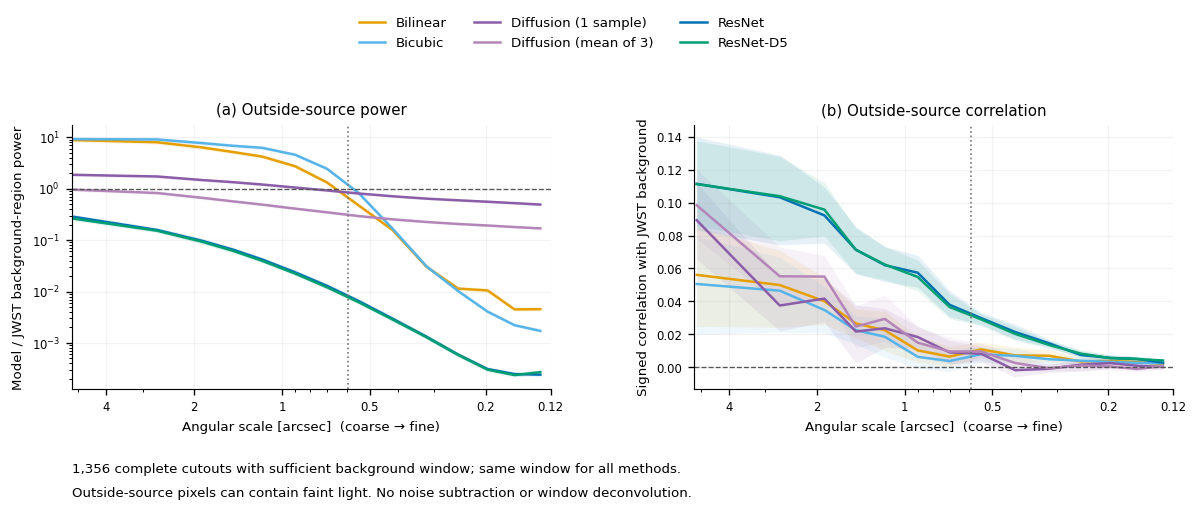

Exported: fig06_spectral_background_v01.pdf, fig06_spectral_background_v01.svg, fig06_spectral_background_v01.png


[PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig06_spectral_background_v01.pdf'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig06_spectral_background_v01.svg'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig06_spectral_background_v01.png')]

In [4]:
# Background-region control: matching noise-like power is not feature recovery.
background=result['summaries']['background']
fig,axes=plt.subplots(1,2,figsize=(10.2,4.0))
for name in names:
    for ax,key,exponent in [(axes[0],'log_power_ratio',True),(axes[1],'correlation',False)]:
        rec=background['methods'][name][key]
        y=np.array(rec['mean'][:nrings]);ci=np.array(rec['ci95'][:nrings])
        if exponent:y=10**y;ci=10**ci
        ax.plot(scale,y,color=colors[name],label=labels[name],lw=1.5)
        ax.fill_between(scale,ci[:,0],ci[:,1],color=colors[name],alpha=.1,lw=0)
axes[0].set_yscale('log');axes[0].axhline(1,color='#555555',ls='--',lw=.8)
axes[0].set_ylabel('Model / JWST background-region power')
axes[0].set_title('(a) Outside-source power')
axes[1].axhline(0,color='#555555',ls='--',lw=.8)
axes[1].set_ylabel('Signed correlation with JWST background')
axes[1].set_title('(b) Outside-source correlation')
for ax in axes:scale_axis(ax)
handles,legend_labels=axes[0].get_legend_handles_labels()
fig.legend(handles,legend_labels,loc='upper center',ncol=3,frameon=False,bbox_to_anchor=(.5,1.05),fontsize=8)
fig.subplots_adjust(left=.09,right=.99,top=.80,bottom=.25,wspace=.3)
fig.text(.09,.075,f"{background['objects']:,} complete cutouts with sufficient background window; same window for all methods.",fontsize=8)
fig.text(.09,.025,'Outside-source pixels can contain faint light. No noise subtraction or window deconvolution.',fontsize=8)
plt.show()
export(fig,f'fig06_spectral_background_{VERSION}','06b_spatial_structure.ipynb',
       [path],dict(objects=background['objects'],window=result['background']),
       status='Outside-source spectral control for texture/noise power and reference correlation')


## Working caption and interpretation limits

Radial Fourier diagnostics of the same cached reconstructions used in Figure 6.
The main population contains 1,363 of 2,118 validation cutouts with complete
common-valid coverage in the central 105×105 field; the 755 incomplete fields
are retained in a separate validity-taper check. Every method and its JWST
reference use the same separable Tukey window, alpha 0.5, after subtracting
their own window-weighted mean. This removes the DC/background level from this
structure diagnostic, not from the earlier pixel-error metrics.

Panel (a) shows the geometric mean per-object power ratio relative to observed
JWST. Panel (b) shows the arithmetic mean of signed annular cross-correlations,
r = Re⟨F_model F_JWST*⟩ / sqrt(⟨|F_model|²⟩⟨|F_JWST|²⟩). Panel (c) shows
reference power relative to an outside-source background proxy with window-energy
normalization. These are raw observed spectra; no noise or PSF correction is
applied. The background window differs, can contain faint sources, and mixes
Fourier modes. Its ratio is a diagnostic rather than calibrated signal-to-noise.
Whisker bands use 2,000 paired spatial-block bootstrap draws. Each cutout has
equal weight in the stated statistic. Angular scales use the sample median
pixel scale only as an axis conversion; the dotted line marks the native NISP
pixel Nyquist wavelength, not a measured effective resolution.

The companion checks vary the outer taper and use a common smooth source weight.
They plot paired differences between diffusion and ResNet-D5 in absolute log-power
mismatch and signed reference correlation. Additional saved band summaries select
objects with reference/background power contrast >3 using reference data only.
Power agreement without correlation improvement is insufficient evidence that
additional structure is recovered in the correct locations. Even high correlation
with a noisy, different-band reference is not a PSF-corrected morphology or shear
measurement. The single diffusion realization is a fixed seed; no best-sample
selection is performed.


A further companion shows outside-source power and reference correlation for
all methods. Diffusion can reproduce appreciable background power with little
correlation to the specific reference noise realization; this must not be
interpreted as recovery of galaxy features.
